## 7. Аналіз поведінки користувачів під час голосування (Voting Behavior Analysis)

In [1]:
# Імпортуємо необхідні бібліотеки

import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

In [2]:
# Знаходимо папку з очищеними даними

current_dir = Path.cwd()

possible_paths = [
    parent / "data_processed"
    for parent in [current_dir, *current_dir.parents]
]

processed_path = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

if processed_path is None:
    raise FileNotFoundError(
        "Не вдалося знайти папку data_processed"
    )

# Завантажуємо очищені датасети

csv_files = sorted(processed_path.glob("*.csv"))

if len(csv_files) != 13:
    raise ValueError(
        f"Очікувалося 13 датасетів, знайдено {len(csv_files)}"
    )

datasets = {
    file.stem: pd.read_csv(file, low_memory=False)
    for file in csv_files
}

# Відновлюємо типи ідентифікаторів

id_columns = [
    "user_id",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id"
]

for df in datasets.values():

    for column in id_columns:

        if column in df.columns:

            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            ).astype("Int64")

    # Відновлюємо числові поля

    numeric_columns = [
        "card_position",
        "likes_count",
        "release_year",
        "runtime_minutes",
        "vote_average"
    ]

    for column in numeric_columns:

        if column in df.columns:

            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            )

    # Відновлюємо часові мітки

    for column in [
        "event_timestamp",
        "started_at",
        "completed_at"
    ]:

        if column in df.columns:

            df[column] = pd.to_datetime(
                df[column],
                errors="coerce",
                utc=True
            )

# Об'єднуємо всі датасети

all_events = pd.concat(
    [
        df.assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Нормалізуємо текстові поля

for column in [
    "event_name",
    "event_value_type",
    "user_type",
    "visitor_id"
]:

    all_events[column] = (
        all_events[column]
        .astype("string")
        .str.strip()
    )

# Нормалізуємо Boolean-значення

all_events["event_value_bool"] = (
    all_events["event_value"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
    .astype("boolean")
)

# Визначаємо Boolean-записи

is_boolean = (
    all_events["event_value_type"]
    .astype("string")
    .str.lower()
    .eq("boolean")
    .fillna(False)
)

# Залишаємо фактичні події

activity_df = all_events[
    (~is_boolean) |
    (all_events["event_value_bool"].fillna(False))
].copy()

# Перевіряємо результат завантаження

print(f"Папка з даними: {processed_path}")
print(f"Кількість датасетів: {len(datasets)}")
print(f"Загальна кількість записів: {len(all_events):,}")
print(f"Кількість фактичних подій: {len(activity_df):,}")

display(activity_df.head())

Папка з даними: c:\Users\ACER\github\analytics\test_analytics\data_processed
Кількість датасетів: 13
Загальна кількість записів: 69,431
Кількість фактичних подій: 47,657


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,dataset,event_value_bool
0,EV00000001,PV_LP_000001,2026-09-15 07:36:31+00:00,create_room_submitted,True,boolean,FRONTEND,visitor_000236,10236,AUTHENTICATED,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
7,EV00000008,PV_LP_000002,2026-10-02 07:13:57+00:00,guest_start_clicked,True,boolean,FRONTEND,visitor_000739,<NA>,GUEST,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
15,EV00000016,PV_LP_000003,2026-10-15 12:32:36+00:00,header_sign_in_clicked,True,boolean,FRONTEND,visitor_000966,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
19,EV00000020,PV_LP_000004,2026-10-19 10:53:39+00:00,guest_start_clicked,True,boolean,FRONTEND,visitor_000967,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
28,EV00000029,PV_LP_000005,2026-10-04 10:12:48+00:00,sign_up_clicked,True,boolean,FRONTEND,visitor_000968,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True


In [3]:
# Визначаємо датасети голосування

swipe_datasets = [
    "06_guest_swipe_session",
    "06_authenticated_swipe_session"
]

# Визначаємо відповідність подій типам голосування

vote_mapping = {
    "swipe_right": True,
    "Like_button": True,
    "movie_liked": True,

    "swipe_left": False,
    "dislike_button": False,
    "movie_disliked": False
}

# Відбираємо події голосування

vote_analysis_raw = activity_df[
    activity_df["dataset"].isin(swipe_datasets) &
    activity_df["event_name"].isin(vote_mapping.keys())
].copy()

# Визначаємо позитивний або негативний голос

vote_analysis_raw["is_liked"] = (
    vote_analysis_raw["event_name"]
    .map(vote_mapping)
    .astype("boolean")
)

vote_analysis_raw["vote_type"] = (
    vote_analysis_raw["is_liked"]
    .map({
        True: "LIKE",
        False: "DISLIKE"
    })
)

# Перевіряємо наявність необхідних ідентифікаторів

vote_key_columns = [
    "room_id",
    "participant_id",
    "room_title_id"
]

missing_key_mask = (
    vote_analysis_raw[vote_key_columns]
    .isna()
    .any(axis=1)
)

missing_vote_keys = vote_analysis_raw[
    missing_key_mask
].copy()

# Залишаємо записи з повними ідентифікаторами

vote_analysis_df = vote_analysis_raw[
    ~missing_key_mask
].copy()

# Перевіряємо повторні голоси

duplicate_votes = vote_analysis_df.duplicated(
    subset=[
        "room_id",
        "participant_id",
        "room_title_id"
    ],
    keep=False
)

duplicate_vote_rows = vote_analysis_df[
    duplicate_votes
].copy()

# Перевіряємо відповідність event_name та is_liked

raw_is_liked = (
    vote_analysis_df["is_liked"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
    .astype("boolean")
)

# Порівнюємо з початковим значенням is_liked

comparison_mask = raw_is_liked.notna()

is_liked_mismatches = (
    raw_is_liked[comparison_mask]
    != vote_analysis_df.loc[
        comparison_mask,
        "is_liked"
    ]
).sum()

# Формуємо звіт

vote_quality_summary = pd.DataFrame([
    {
        "check": "Total vote records",
        "result": len(vote_analysis_raw)
    },
    {
        "check": "Records with missing identifiers",
        "result": len(missing_vote_keys)
    },
    {
        "check": "Records involved in duplicate vote keys",
        "result": len(duplicate_vote_rows)
    },
    {
        "check": "is_liked mismatches",
        "result": int(is_liked_mismatches)
    },
    {
        "check": "Valid vote records",
        "result": len(vote_analysis_df)
    }
])

display(vote_quality_summary)

# Перевіряємо розподіл типів подій

vote_event_summary = (
    vote_analysis_df
    .groupby(["event_name", "vote_type"])
    .agg(
        total_votes=("event_id", "count")
    )
    .reset_index()
    .sort_values("total_votes", ascending=False)
)

display(vote_event_summary)

,check,result
0,Total vote records,34000
1,Records with missing identifiers,0
2,Records involved in duplicate vote keys,0
3,is_liked mismatches,0
4,Valid vote records,34000


,event_name,vote_type,total_votes
3,movie_liked,LIKE,7995
5,swipe_right,LIKE,7628
2,movie_disliked,DISLIKE,6705
4,swipe_left,DISLIKE,6309
0,Like_button,LIKE,2883
1,dislike_button,DISLIKE,2480


In [4]:
# Розраховуємо загальні показники голосування

total_votes = len(vote_analysis_df)

total_likes = int(
    vote_analysis_df["is_liked"].sum()
)

total_dislikes = total_votes - total_likes

unique_rooms = (
    vote_analysis_df["room_id"].nunique()
)

unique_participant_sessions = (
    vote_analysis_df[
        ["room_id", "participant_id"]
    ]
    .drop_duplicates()
    .shape[0]
)

unique_participants = (
    vote_analysis_df["participant_id"].nunique()
)

unique_movies = (
    vote_analysis_df["title_id"].nunique()
)

unique_room_cards = (
    vote_analysis_df["room_title_id"].nunique()
)

# Розраховуємо частки позитивних та негативних голосів

like_rate_pct = (
    total_likes / total_votes * 100
    if total_votes > 0 else 0
)

dislike_rate_pct = (
    total_dislikes / total_votes * 100
    if total_votes > 0 else 0
)

# Розраховуємо середню кількість голосів на одну сесію учасника

avg_votes_per_participant = (
    total_votes / unique_participant_sessions
    if unique_participant_sessions > 0 else 0
)

# Формуємо таблицю основних показників

voting_kpi = pd.DataFrame([
    {
        "metric": "Total votes",
        "value": total_votes,
        "unit": "votes"
    },
    {
        "metric": "Positive votes",
        "value": total_likes,
        "unit": "votes"
    },
    {
        "metric": "Negative votes",
        "value": total_dislikes,
        "unit": "votes"
    },
    {
        "metric": "Like rate",
        "value": like_rate_pct,
        "unit": "%"
    },
    {
        "metric": "Dislike rate",
        "value": dislike_rate_pct,
        "unit": "%"
    },
    {
        "metric": "Unique rooms",
        "value": unique_rooms,
        "unit": "rooms"
    },
    {
        "metric": "Participant sessions",
        "value": unique_participant_sessions,
        "unit": "room-participant pairs"
    },
    {
        "metric": "Unique participants",
        "value": unique_participants,
        "unit": "participants"
    },
    {
        "metric": "Unique movies",
        "value": unique_movies,
        "unit": "movies"
    },
    {
        "metric": "Unique room movie cards",
        "value": unique_room_cards,
        "unit": "cards"
    },
    {
        "metric": "Average votes per participant session",
        "value": avg_votes_per_participant,
        "unit": "votes"
    }
])

display(voting_kpi.round(2))

# Формуємо розподіл позитивних та негативних голосів

vote_type_summary = pd.DataFrame({
    "vote_type": ["LIKE", "DISLIKE"],
    "total_votes": [total_likes, total_dislikes],
    "share_pct": [like_rate_pct, dislike_rate_pct]
})

display(vote_type_summary.round(2))

,metric,value,unit
0,Total votes,34000.00,votes
1,Positive votes,18506.00,votes
2,Negative votes,15494.00,votes
3,Like rate,54.43,%
4,Dislike rate,45.57,%
5,Unique rooms,500.00,rooms
6,Participant sessions,1700.00,room-participant pairs
7,Unique participants,1700.00,participants
8,Unique movies,3445.00,movies
9,Unique room movie cards,10000.00,cards


,vote_type,total_votes,share_pct
0,LIKE,18506,54.43
1,DISLIKE,15494,45.57


In [5]:
# Розраховуємо кількість голосів для кожного учасника в кожній кімнаті

participant_vote_summary = (
    vote_analysis_df
    .groupby(
        ["user_type", "room_id", "participant_id"]
    )
    .agg(
        total_votes=("event_id", "count"),
        unique_movies=("room_title_id", "nunique"),
        unique_titles=("title_id", "nunique"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

# Розраховуємо кількість негативних голосів

participant_vote_summary["dislikes"] = (
    participant_vote_summary["total_votes"]
    - participant_vote_summary["likes"]
)

# Розраховуємо частку позитивних та негативних голосів

participant_vote_summary["like_rate_pct"] = (
    participant_vote_summary["likes"]
    / participant_vote_summary["total_votes"]
    * 100
)

participant_vote_summary["dislike_rate_pct"] = (
    participant_vote_summary["dislikes"]
    / participant_vote_summary["total_votes"]
    * 100
)

# Формуємо загальну статистику за типами користувачів

participant_behavior_summary = (
    participant_vote_summary
    .groupby("user_type")
    .agg(
        participant_sessions=("participant_id", "count"),
        avg_votes=("total_votes", "mean"),
        median_votes=("total_votes", "median"),
        avg_unique_movies=("unique_movies", "mean"),
        avg_likes=("likes", "mean"),
        avg_dislikes=("dislikes", "mean"),
        avg_like_rate_pct=("like_rate_pct", "mean"),
        median_like_rate_pct=("like_rate_pct", "median")
    )
    .reset_index()
)

# Додаємо сумарну кількість голосів за сегментами

segment_vote_totals = (
    vote_analysis_df
    .groupby("user_type")
    .agg(
        total_votes=("event_id", "count"),
        total_likes=("is_liked", "sum")
    )
    .reset_index()
)

segment_vote_totals["weighted_like_rate_pct"] = (
    segment_vote_totals["total_likes"]
    / segment_vote_totals["total_votes"]
    * 100
)

participant_behavior_summary = (
    participant_behavior_summary
    .merge(
        segment_vote_totals[
            [
                "user_type",
                "total_votes",
                "weighted_like_rate_pct"
            ]
        ],
        on="user_type",
        how="left"
    )
)

display(participant_behavior_summary.round(2))

,user_type,participant_sessions,avg_votes,median_votes,avg_unique_movies,avg_likes,avg_dislikes,avg_like_rate_pct,median_like_rate_pct,total_votes,weighted_like_rate_pct
0,AUTHENTICATED,735,20.0,20.0,20.0,10.88,9.12,54.39,55.0,14700,54.39
1,GUEST,965,20.0,20.0,20.0,10.89,9.11,54.46,55.0,19300,54.46


In [6]:
# Аналізуємо розподіл кількості голосів на одного учасника

participant_vote_count_distribution = (
    participant_vote_summary
    .groupby(["user_type", "total_votes"])
    .size()
    .reset_index(name="participant_sessions")
    .sort_values(["user_type", "total_votes"])
)

# Розраховуємо частку учасників із різною кількістю голосів

participant_vote_count_distribution["share_pct"] = (
    participant_vote_count_distribution["participant_sessions"]
    / participant_vote_count_distribution
        .groupby("user_type")["participant_sessions"]
        .transform("sum")
    * 100
)

display(
    participant_vote_count_distribution.round(2)
)

# Формуємо загальну перевірку кількості голосів

participant_vote_completeness = (
    participant_vote_summary
    .groupby("user_type")
    .agg(
        total_participant_sessions=("participant_id", "count"),
        sessions_with_20_votes=(
            "total_votes",
            lambda x: (x == 20).sum()
        ),
        sessions_with_less_than_20=(
            "total_votes",
            lambda x: (x < 20).sum()
        ),
        sessions_with_more_than_20=(
            "total_votes",
            lambda x: (x > 20).sum()
        )
    )
    .reset_index()
)

participant_vote_completeness["sessions_with_20_votes_pct"] = (
    participant_vote_completeness["sessions_with_20_votes"]
    / participant_vote_completeness["total_participant_sessions"]
    * 100
)

display(
    participant_vote_completeness.round(2)
)

,user_type,total_votes,participant_sessions,share_pct
0,AUTHENTICATED,20,735,100.0
1,GUEST,20,965,100.0


,user_type,total_participant_sessions,sessions_with_20_votes,sessions_with_less_than_20,sessions_with_more_than_20,sessions_with_20_votes_pct
0,AUTHENTICATED,735,735,0,0,100.0
1,GUEST,965,965,0,0,100.0


In [7]:
# Аналізуємо голосування на рівні ігрових кімнат

room_vote_summary = (
    vote_analysis_df
    .groupby(["user_type", "room_id"])
    .agg(
        total_votes=("event_id", "count"),
        participants=("participant_id", "nunique"),
        unique_movies=("room_title_id", "nunique"),
        likes=("is_liked", "sum")
    )
    .reset_index()
)

# Розраховуємо негативні голоси

room_vote_summary["dislikes"] = (
    room_vote_summary["total_votes"]
    - room_vote_summary["likes"]
)

# Розраховуємо кількість голосів на одного учасника

room_vote_summary["votes_per_participant"] = (
    room_vote_summary["total_votes"]
    / room_vote_summary["participants"].replace(0, pd.NA)
)

# Розраховуємо частку позитивних голосів

room_vote_summary["like_rate_pct"] = (
    room_vote_summary["likes"]
    / room_vote_summary["total_votes"]
    * 100
)

# Формуємо загальну статистику розміру груп

group_size_summary = (
    room_vote_summary
    .groupby(["user_type", "participants"])
    .agg(
        rooms=("room_id", "nunique"),
        avg_total_votes=("total_votes", "mean"),
        avg_votes_per_participant=("votes_per_participant", "mean"),
        avg_unique_movies=("unique_movies", "mean"),
        avg_like_rate_pct=("like_rate_pct", "mean")
    )
    .reset_index()
    .sort_values(["user_type", "participants"])
)

display(group_size_summary.round(2))

# Розраховуємо загальну статистику розміру груп

group_size_statistics = pd.DataFrame({
    "metric": [
        "Total rooms",
        "Total participant instances",
        "Average participants per room",
        "Median participants per room",
        "Minimum group size",
        "Maximum group size"
    ],
    "value": [
        room_vote_summary["room_id"].nunique(),
        room_vote_summary["participants"].sum(),
        room_vote_summary["participants"].mean(),
        room_vote_summary["participants"].median(),
        room_vote_summary["participants"].min(),
        room_vote_summary["participants"].max()
    ]
})

display(group_size_statistics.round(2))

,user_type,participants,rooms,avg_total_votes,avg_votes_per_participant,avg_unique_movies,avg_like_rate_pct
0,AUTHENTICATED,1,183,20.0,20.0,20.0,52.79
1,AUTHENTICATED,2,159,40.0,20.0,20.0,54.51
2,AUTHENTICATED,3,62,60.0,20.0,20.0,55.56
3,AUTHENTICATED,4,12,80.0,20.0,20.0,55.1
4,GUEST,1,135,20.0,20.0,20.0,53.89
5,GUEST,2,183,40.0,20.0,20.0,54.32
6,GUEST,3,106,60.0,20.0,20.0,54.72
7,GUEST,4,34,80.0,20.0,20.0,54.56
8,GUEST,5,2,100.0,20.0,20.0,58.0


,metric,value
0,Total rooms,500.00
1,Total participant instances,1700.00
2,Average participants per room,1.94
3,Median participants per room,2.00
4,Minimum group size,1.00
5,Maximum group size,5.00


In [8]:
# Формуємо таблицю голосування за розміром групи

vote_group_summary = (
    room_vote_summary
    .groupby(["user_type", "participants"])
    .agg(
        rooms=("room_id", "nunique"),
        total_votes=("total_votes", "sum"),
        likes=("likes", "sum"),
        dislikes=("dislikes", "sum")
    )
    .reset_index()
)

# Розраховуємо частку позитивних голосів

vote_group_summary["like_rate_pct"] = (
    vote_group_summary["likes"]
    / vote_group_summary["total_votes"]
    * 100
)

# Розраховуємо частку негативних голосів

vote_group_summary["dislike_rate_pct"] = (
    vote_group_summary["dislikes"]
    / vote_group_summary["total_votes"]
    * 100
)

display(
    vote_group_summary.round(2)
)

,user_type,participants,rooms,total_votes,likes,dislikes,like_rate_pct,dislike_rate_pct
0,AUTHENTICATED,1,183,3660,1932,1728,52.79,47.21
1,AUTHENTICATED,2,159,6360,3467,2893,54.51,45.49
2,AUTHENTICATED,3,62,3720,2067,1653,55.56,44.44
3,AUTHENTICATED,4,12,960,529,431,55.1,44.9
4,GUEST,1,135,2700,1455,1245,53.89,46.11
5,GUEST,2,183,7320,3976,3344,54.32,45.68
6,GUEST,3,106,6360,3480,2880,54.72,45.28
7,GUEST,4,34,2720,1484,1236,54.56,45.44
8,GUEST,5,2,200,116,84,58.0,42.0


In [9]:
# Перетворюємо позицію картки у числовий формат

vote_analysis_df["card_position"] = pd.to_numeric(
    vote_analysis_df["card_position"],
    errors="coerce"
)

# Відбираємо голоси з відомою позицією фільму

position_votes = vote_analysis_df.dropna(
    subset=["card_position"]
).copy()

# Розраховуємо кількість позитивних та негативних голосів за позицією

position_summary = (
    position_votes
    .groupby("card_position")
    .agg(
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum"),
        unique_rooms=("room_id", "nunique"),
        unique_movies=("title_id", "nunique")
    )
    .reset_index()
    .sort_values("card_position")
)

# Розраховуємо кількість дизлайків

position_summary["dislikes"] = (
    position_summary["total_votes"]
    - position_summary["likes"]
)

# Розраховуємо частки голосів

position_summary["like_rate_pct"] = (
    position_summary["likes"]
    / position_summary["total_votes"]
    * 100
)

position_summary["dislike_rate_pct"] = (
    position_summary["dislikes"]
    / position_summary["total_votes"]
    * 100
)

display(position_summary.round(2))

# Перевіряємо діапазон позицій

print(
    "Мінімальна позиція:",
    position_summary["card_position"].min()
)

print(
    "Максимальна позиція:",
    position_summary["card_position"].max()
)

print(
    "Кількість різних позицій:",
    position_summary["card_position"].nunique()
)

,card_position,total_votes,likes,unique_rooms,unique_movies,dislikes,like_rate_pct,dislike_rate_pct
0,0.0,1700,909,500,446,791,53.47,46.53
1,1.0,1700,945,500,442,755,55.59,44.41
2,2.0,1700,946,500,455,754,55.65,44.35
3,3.0,1700,916,500,445,784,53.88,46.12
4,4.0,1700,930,500,446,770,54.71,45.29
5,5.0,1700,913,500,439,787,53.71,46.29
6,6.0,1700,926,500,441,774,54.47,45.53
7,7.0,1700,937,500,457,763,55.12,44.88
8,8.0,1700,923,500,451,777,54.29,45.71
9,9.0,1700,927,500,447,773,54.53,45.47


Мінімальна позиція: 0.0
Максимальна позиція: 19.0
Кількість різних позицій: 20


In [10]:
# Функція для розбору JSON зі списком жанрів

def parse_genres(value):

    if pd.isna(value):
        return []

    try:

        parsed = json.loads(str(value))

        if isinstance(parsed, list):
            return parsed

        return []

    except (ValueError, TypeError):
        return []


# Відбираємо голоси з інформацією про жанри

genre_votes = vote_analysis_df[
    [
        "event_id",
        "room_id",
        "participant_id",
        "title_id",
        "genres_json",
        "is_liked"
    ]
].copy()

# Перетворюємо JSON-рядки на списки жанрів

genre_votes["genres"] = (
    genre_votes["genres_json"]
    .apply(parse_genres)
)

# Розгортаємо списки жанрів

genre_votes = genre_votes.explode("genres")

# Видаляємо записи без інформації про жанр

genre_votes = genre_votes.dropna(
    subset=["genres"]
)

# Видаляємо повтори жанрів у межах одного голосу

genre_votes = genre_votes.drop_duplicates(
    subset=["event_id", "genres"]
)

# Розраховуємо статистику голосування за жанрами

genre_summary = (
    genre_votes
    .groupby("genres")
    .agg(
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum"),
        unique_movies=("title_id", "nunique"),
        unique_rooms=("room_id", "nunique")
    )
    .reset_index()
    .rename(columns={"genres": "genre"})
)

# Розраховуємо кількість дизлайків

genre_summary["dislikes"] = (
    genre_summary["total_votes"]
    - genre_summary["likes"]
)

# Розраховуємо частку позитивних голосів

genre_summary["like_rate_pct"] = (
    genre_summary["likes"]
    / genre_summary["total_votes"]
    * 100
)

# Сортуємо жанри за кількістю голосів

genre_summary = genre_summary.sort_values(
    "total_votes",
    ascending=False
).reset_index(drop=True)

display(
    genre_summary.round(2)
)

# Визначаємо 10 найпопулярніших жанрів за кількістю голосів

top_genres = genre_summary.head(10).copy()

display(top_genres.round(2))

,genre,total_votes,likes,unique_movies,unique_rooms,dislikes,like_rate_pct
0,Mystery,4501,2471,378,414,2030,54.9
1,Music,4497,2499,424,438,1998,55.57
2,Western,4477,2439,404,419,2038,54.48
3,Science Fiction,4392,2384,441,420,2008,54.28
4,Drama,4378,2372,420,418,2006,54.18
5,Horror,4199,2326,402,382,1873,55.39
6,History,4192,2278,426,421,1914,54.34
7,Animation,4158,2331,376,413,1827,56.06
8,Romance,4099,2229,382,409,1870,54.38
9,Adventure,4004,2208,367,414,1796,55.14


,genre,total_votes,likes,unique_movies,unique_rooms,dislikes,like_rate_pct
0,Mystery,4501,2471,378,414,2030,54.9
1,Music,4497,2499,424,438,1998,55.57
2,Western,4477,2439,404,419,2038,54.48
3,Science Fiction,4392,2384,441,420,2008,54.28
4,Drama,4378,2372,420,418,2006,54.18
5,Horror,4199,2326,402,382,1873,55.39
6,History,4192,2278,426,421,1914,54.34
7,Animation,4158,2331,376,413,1827,56.06
8,Romance,4099,2229,382,409,1870,54.38
9,Adventure,4004,2208,367,414,1796,55.14


In [11]:
# Відбираємо голоси з інформацією про фільми

movie_votes = vote_analysis_df.dropna(
    subset=["title_id", "title"]
).copy()

# Розраховуємо статистику голосування для кожного фільму

movie_summary = (
    movie_votes
    .groupby(["title_id", "title"])
    .agg(
        total_votes=("event_id", "count"),
        likes=("is_liked", "sum"),
        unique_rooms=("room_id", "nunique"),
        unique_participants=("participant_id", "nunique"),
        vote_average=("vote_average", "mean"),
        release_year=("release_year", "first")
    )
    .reset_index()
)

# Розраховуємо кількість дизлайків

movie_summary["dislikes"] = (
    movie_summary["total_votes"]
    - movie_summary["likes"]
)

# Розраховуємо частку позитивних голосів

movie_summary["like_rate_pct"] = (
    movie_summary["likes"]
    / movie_summary["total_votes"]
    * 100
)

# Визначаємо мінімальну кількість голосів для порівняння фільмів

min_votes_per_movie = 20

eligible_movies = movie_summary[
    movie_summary["total_votes"] >= min_votes_per_movie
].copy()

print(
    "Кількість фільмів у вибірці:",
    len(movie_summary)
)

print(
    f"Кількість фільмів із не менше ніж "
    f"{min_votes_per_movie} голосами:",
    len(eligible_movies)
)

# Визначаємо 10 фільмів із найбільшою кількістю голосів

top_movies_by_votes = (
    movie_summary
    .nlargest(10, "total_votes")
)

print("Топ-10 фільмів за кількістю голосів:")

display(
    top_movies_by_votes.round(2)
)

# Визначаємо фільми з найбільшою часткою позитивних голосів

top_movies_by_like_rate = (
    eligible_movies
    .nlargest(10, "like_rate_pct")
)

print("Топ-10 фільмів за часткою позитивних голосів:")

display(
    top_movies_by_like_rate.round(2)
)

# Визначаємо фільми з найменшою часткою позитивних голосів

bottom_movies_by_like_rate = (
    eligible_movies
    .nsmallest(10, "like_rate_pct")
)

print("10 фільмів із найменшою часткою позитивних голосів:")

display(
    bottom_movies_by_like_rate.round(2)
)

Кількість фільмів у вибірці: 3445
Кількість фільмів із не менше ніж 20 голосами: 441
Топ-10 фільмів за кількістю голосів:


,title_id,title,total_votes,likes,unique_rooms,unique_participants,vote_average,release_year,dislikes,like_rate_pct
857,801305,The Lonely Symphony 1305,63,35,19,63,8.55,1996.0,28,55.56
323,800518,The Winter Horizon 0518,62,34,17,62,6.91,1994.0,28,54.84
1785,802764,The Secret Library 2764,62,31,17,62,7.91,2002.0,31,50.0
654,801021,The Northern Portrait 1021,60,32,16,60,8.21,1995.0,28,53.33
545,800853,The Hidden Letter 0853,59,39,16,59,5.10,2026.0,20,66.1
812,801237,The Distant Signal 1237,59,27,17,59,7.28,2020.0,32,45.76
1065,801648,The Glass Harbour 1648,59,30,16,59,8.64,2009.0,29,50.85
1197,801847,The Glass Echo 1847,59,36,17,59,8.86,1980.0,23,61.02
1258,801951,The Midnight Horizon 1951,58,30,19,58,5.79,2000.0,28,51.72
1902,802963,The Golden Mirage 2963,58,31,18,58,8.56,1988.0,27,53.45


Топ-10 фільмів за часткою позитивних голосів:


,title_id,title,total_votes,likes,unique_rooms,unique_participants,vote_average,release_year,dislikes,like_rate_pct
219,800358,The Broken Passage 0358,26,22,10,26,6.06,2018.0,4,84.62
1518,802346,The Wild Horizon 2346,31,24,8,31,5.06,2009.0,7,77.42
1570,802423,The Parallel Orbit 2423,21,16,7,21,6.76,2008.0,5,76.19
1215,801883,The Lonely Horizon 1883,25,19,7,25,5.45,1981.0,6,76.0
340,800545,The Strange Ocean 0545,29,22,9,29,5.07,2011.0,7,75.86
751,801150,The Golden Signal 1150,37,28,11,37,8.86,1980.0,9,75.68
525,800827,The Infinite Lantern 0827,20,15,6,20,6.75,1984.0,5,75.0
1096,801695,The Electric Orbit 1695,20,15,6,20,7.61,1988.0,5,75.0
1701,802635,The Strange Portrait 2635,39,29,11,39,8.85,2009.0,10,74.36
145,800243,The Silver City 0243,23,17,7,23,5.97,2003.0,6,73.91


10 фільмів із найменшою часткою позитивних голосів:


,title_id,title,total_votes,likes,unique_rooms,unique_participants,vote_average,release_year,dislikes,like_rate_pct
420,800659,The Infinite Horizon 0659,37,11,12,37,8.13,1981.0,26,29.73
1849,802876,The Fading City 2876,26,8,7,26,6.38,2014.0,18,30.77
214,800351,The Forgotten Horizon 0351,24,8,6,24,6.37,2022.0,16,33.33
1008,801569,The Lonely Memory 1569,21,7,6,21,7.78,1985.0,14,33.33
1599,802468,The Winter Memory 2468,47,16,14,47,8.56,1997.0,31,34.04
126,800212,The Silver Letter 0212,20,7,7,20,4.87,2010.0,13,35.0
1313,802041,The Strange Echo 2041,34,12,9,34,7.81,1982.0,22,35.29
508,800800,The Hidden Mirage 0800,39,14,11,39,8.04,1997.0,25,35.9
996,801554,The Silent Portrait 1554,30,11,10,30,6.33,1982.0,19,36.67
1665,802577,The Paper Compass 2577,30,11,9,30,8.76,2006.0,19,36.67


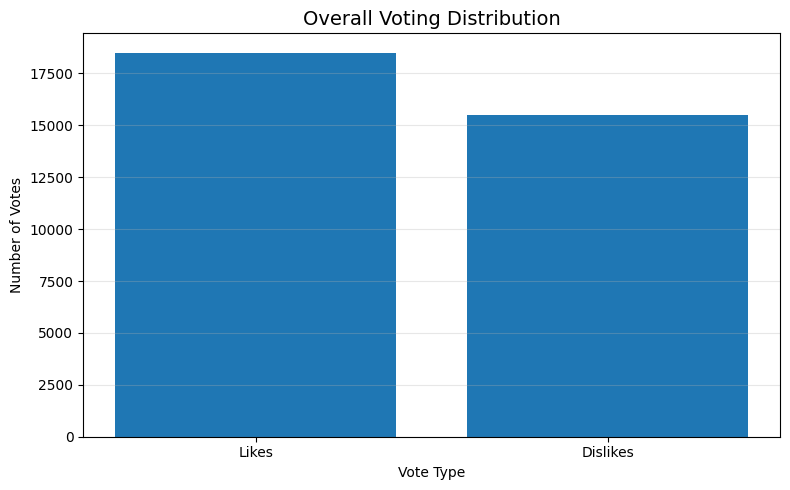

In [12]:
# Візуалізуємо загальний розподіл голосів

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Likes", "Dislikes"],
    [total_likes, total_dislikes]
)

ax.set_title("Overall Voting Distribution", fontsize=14)
ax.set_xlabel("Vote Type")
ax.set_ylabel("Number of Votes")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

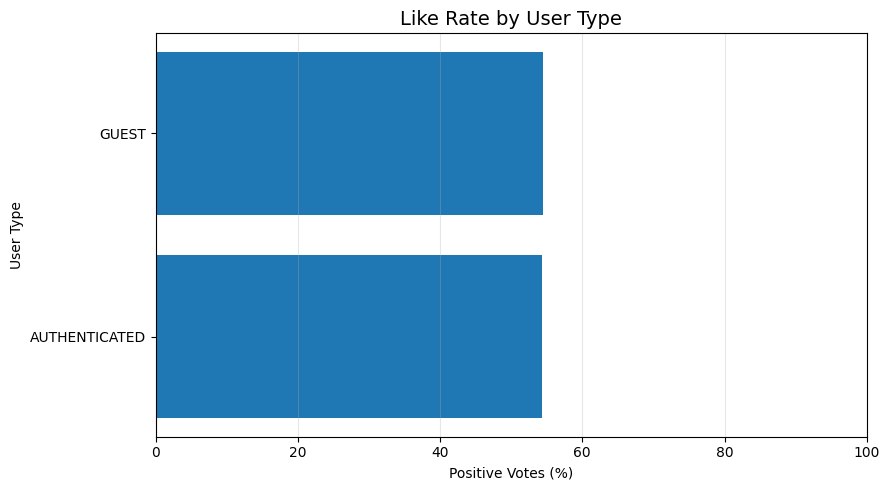

In [13]:
# Візуалізуємо частку позитивних голосів за типами користувачів

segment_plot = (
    segment_vote_totals
    .sort_values("weighted_like_rate_pct", ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    segment_plot["user_type"],
    segment_plot["weighted_like_rate_pct"]
)

ax.set_title("Like Rate by User Type", fontsize=14)
ax.set_xlabel("Positive Votes (%)")
ax.set_ylabel("User Type")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

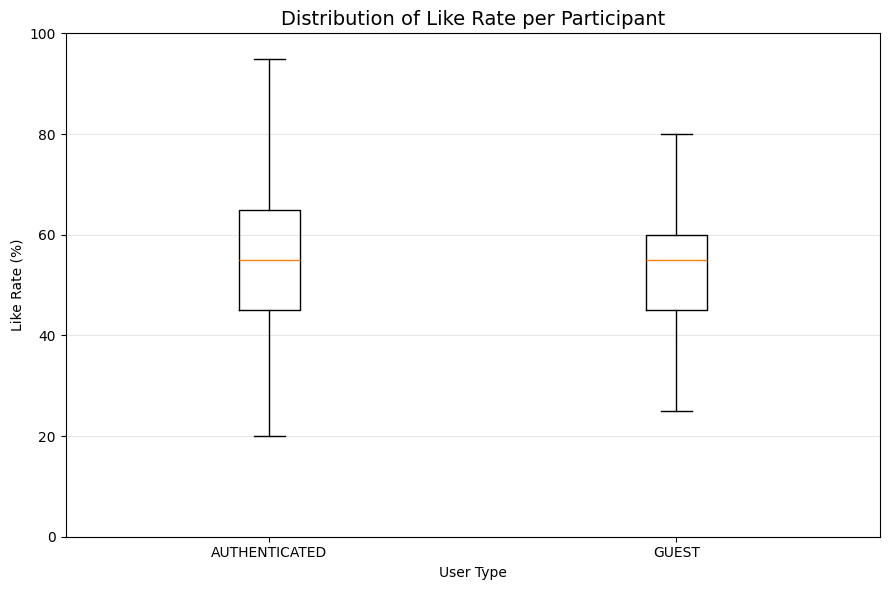

In [14]:
# Готуємо дані для Boxplot

user_types_order = sorted(
    participant_vote_summary["user_type"]
    .dropna()
    .unique()
)

boxplot_data = [
    participant_vote_summary.loc[
        participant_vote_summary["user_type"] == user_type,
        "like_rate_pct"
    ].values
    for user_type in user_types_order
]

# Візуалізуємо індивідуальну частку лайків

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    boxplot_data,
    showfliers=False
)

ax.set_xticks(
    range(1, len(user_types_order) + 1)
)

ax.set_xticklabels(user_types_order)

ax.set_title("Distribution of Like Rate per Participant", fontsize=14)
ax.set_xlabel("User Type")
ax.set_ylabel("Like Rate (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

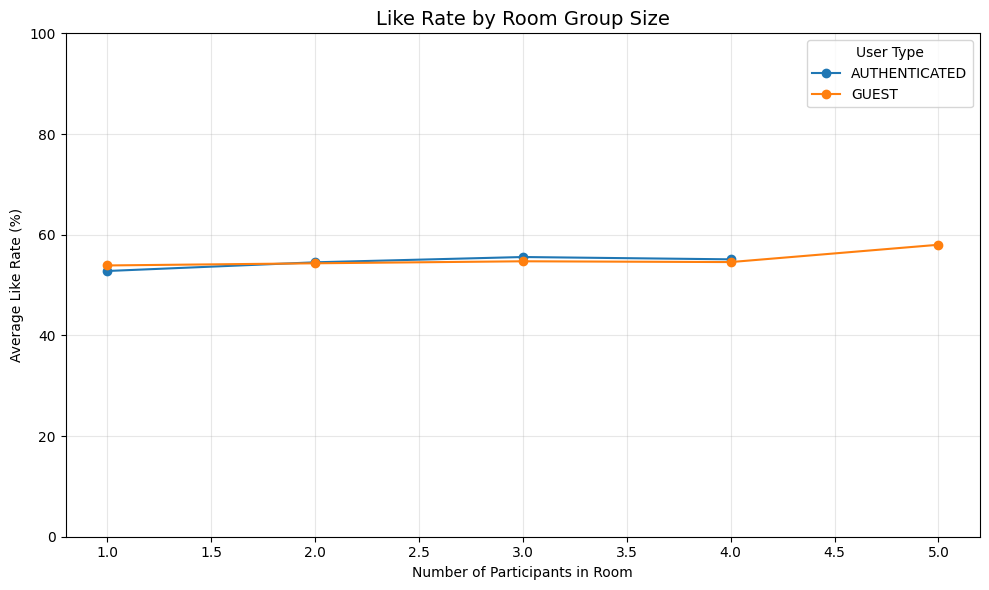

In [15]:
# Формуємо таблицю середньої частки лайків за розміром групи

group_like_pivot = (
    group_size_summary
    .pivot(
        index="participants",
        columns="user_type",
        values="avg_like_rate_pct"
    )
    .sort_index()
)

# Візуалізуємо залежність частки лайків від розміру групи

fig, ax = plt.subplots(figsize=(10, 6))

for user_type in group_like_pivot.columns:

    ax.plot(
        group_like_pivot.index,
        group_like_pivot[user_type],
        marker="o",
        label=user_type
    )

ax.set_title("Like Rate by Room Group Size", fontsize=14)
ax.set_xlabel("Number of Participants in Room")
ax.set_ylabel("Average Like Rate (%)")
ax.set_ylim(0, 100)
ax.legend(title="User Type")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

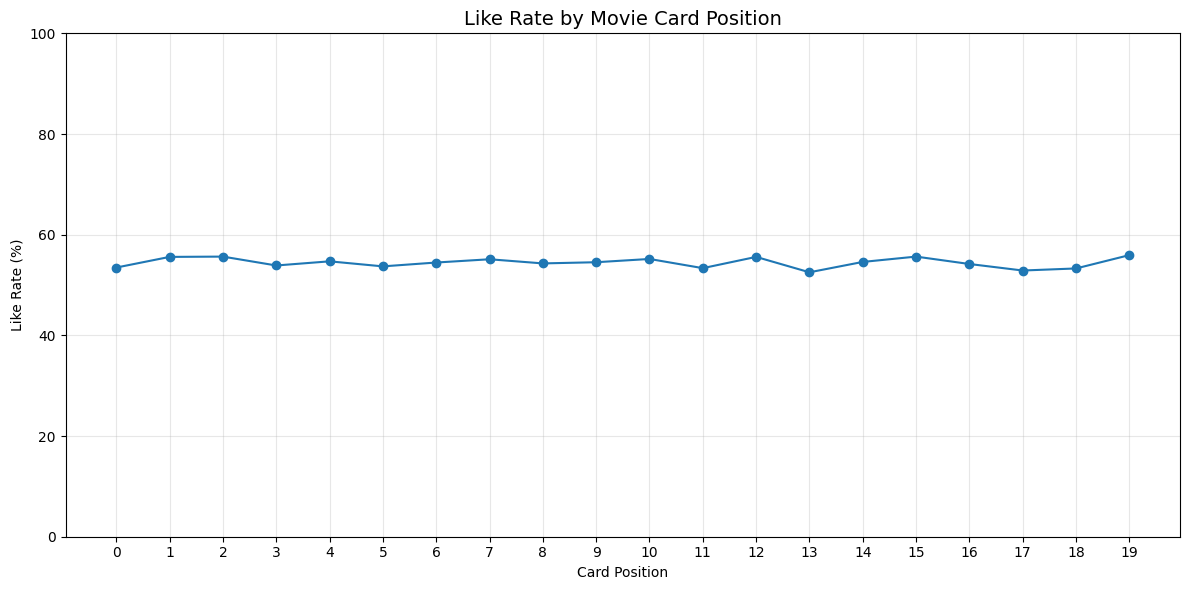

In [16]:
# Візуалізуємо частку позитивних голосів залежно від позиції картки

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    position_summary["card_position"],
    position_summary["like_rate_pct"],
    marker="o"
)

ax.set_title("Like Rate by Movie Card Position", fontsize=14)
ax.set_xlabel("Card Position")
ax.set_ylabel("Like Rate (%)")
ax.set_ylim(0, 100)
ax.set_xticks(
    sorted(position_summary["card_position"].unique())
)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

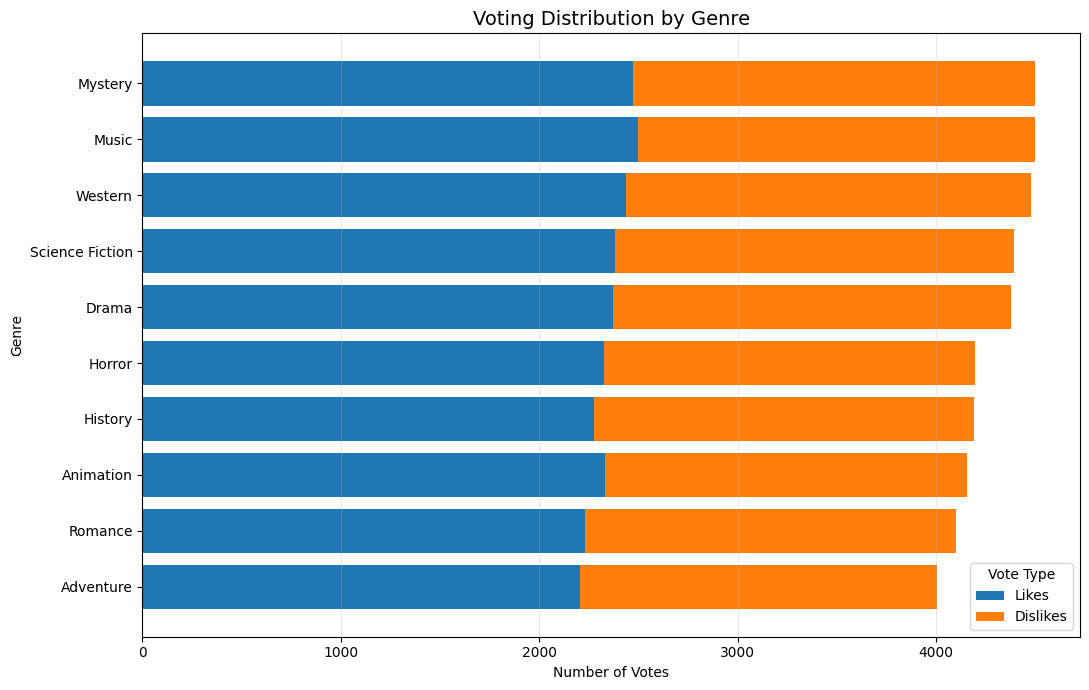

In [17]:
# Готуємо дані для візуалізації топ-10 жанрів

genre_plot = (
    top_genres
    .sort_values("total_votes", ascending=True)
    .set_index("genre")
)

# Візуалізуємо позитивні та негативні голоси за жанрами

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    genre_plot.index,
    genre_plot["likes"],
    label="Likes"
)

ax.barh(
    genre_plot.index,
    genre_plot["dislikes"],
    left=genre_plot["likes"],
    label="Dislikes"
)

ax.set_title("Voting Distribution by Genre", fontsize=14)
ax.set_xlabel("Number of Votes")
ax.set_ylabel("Genre")
ax.legend(title="Vote Type")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

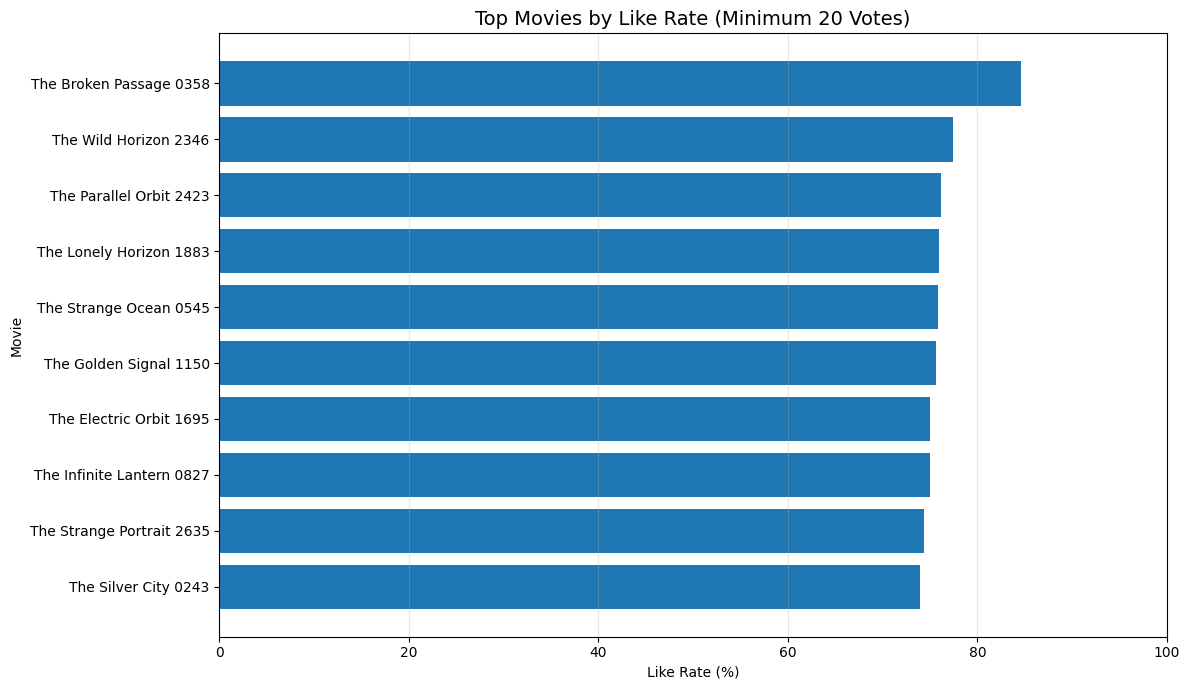

In [18]:
# Візуалізуємо фільми з найбільшою часткою позитивних голосів

movie_plot = (
    top_movies_by_like_rate
    .sort_values("like_rate_pct", ascending=True)
)

if not movie_plot.empty:

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.barh(
        movie_plot["title"],
        movie_plot["like_rate_pct"]
    )

    ax.set_title(
        f"Top Movies by Like Rate "
        f"(Minimum {min_votes_per_movie} Votes)",
        fontsize=14
    )

    ax.set_xlabel("Like Rate (%)")
    ax.set_ylabel("Movie")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

else:

    print(
        "Недостатньо фільмів із заданою мінімальною кількістю голосів."
    )

In [19]:
# Формуємо підсумкову таблицю голосування

voting_final_summary = pd.DataFrame([
    {
        "metric": "Total votes",
        "value": total_votes,
        "unit": "votes"
    },
    {
        "metric": "Positive votes",
        "value": total_likes,
        "unit": "votes"
    },
    {
        "metric": "Negative votes",
        "value": total_dislikes,
        "unit": "votes"
    },
    {
        "metric": "Like rate",
        "value": like_rate_pct,
        "unit": "%"
    },
    {
        "metric": "Dislike rate",
        "value": dislike_rate_pct,
        "unit": "%"
    },
    {
        "metric": "Unique rooms",
        "value": unique_rooms,
        "unit": "rooms"
    },
    {
        "metric": "Participant sessions",
        "value": unique_participant_sessions,
        "unit": "sessions"
    },
    {
        "metric": "Average votes per participant",
        "value": avg_votes_per_participant,
        "unit": "votes"
    },
    {
        "metric": "Unique movies",
        "value": unique_movies,
        "unit": "movies"
    },
    {
        "metric": "Unique room movie cards",
        "value": unique_room_cards,
        "unit": "cards"
    }
])

display(voting_final_summary.round(2))

# Виводимо підсумки за типами користувачів

print("Поведінка учасників за типами користувачів:")

display(
    participant_behavior_summary.round(2)
)

# Виводимо результати аналізу кімнат

print("Голосування залежно від розміру групи:")

display(
    group_size_summary.round(2)
)

# Виводимо результати аналізу позицій карток

print("Голосування залежно від позиції фільму:")

display(
    position_summary.round(2)
)

# Виводимо результати аналізу жанрів

print("Голосування за жанрами:")

display(
    genre_summary.round(2)
)

# Виводимо результати аналізу фільмів

print("Рейтинг фільмів за часткою позитивних голосів:")

display(
    top_movies_by_like_rate.round(2)
)

,metric,value,unit
0,Total votes,34000.00,votes
1,Positive votes,18506.00,votes
2,Negative votes,15494.00,votes
3,Like rate,54.43,%
4,Dislike rate,45.57,%
5,Unique rooms,500.00,rooms
6,Participant sessions,1700.00,sessions
7,Average votes per participant,20.00,votes
8,Unique movies,3445.00,movies
9,Unique room movie cards,10000.00,cards


Поведінка учасників за типами користувачів:


,user_type,participant_sessions,avg_votes,median_votes,avg_unique_movies,avg_likes,avg_dislikes,avg_like_rate_pct,median_like_rate_pct,total_votes,weighted_like_rate_pct
0,AUTHENTICATED,735,20.0,20.0,20.0,10.88,9.12,54.39,55.0,14700,54.39
1,GUEST,965,20.0,20.0,20.0,10.89,9.11,54.46,55.0,19300,54.46


Голосування залежно від розміру групи:


,user_type,participants,rooms,avg_total_votes,avg_votes_per_participant,avg_unique_movies,avg_like_rate_pct
0,AUTHENTICATED,1,183,20.0,20.0,20.0,52.79
1,AUTHENTICATED,2,159,40.0,20.0,20.0,54.51
2,AUTHENTICATED,3,62,60.0,20.0,20.0,55.56
3,AUTHENTICATED,4,12,80.0,20.0,20.0,55.1
4,GUEST,1,135,20.0,20.0,20.0,53.89
5,GUEST,2,183,40.0,20.0,20.0,54.32
6,GUEST,3,106,60.0,20.0,20.0,54.72
7,GUEST,4,34,80.0,20.0,20.0,54.56
8,GUEST,5,2,100.0,20.0,20.0,58.0


Голосування залежно від позиції фільму:


,card_position,total_votes,likes,unique_rooms,unique_movies,dislikes,like_rate_pct,dislike_rate_pct
0,0.0,1700,909,500,446,791,53.47,46.53
1,1.0,1700,945,500,442,755,55.59,44.41
2,2.0,1700,946,500,455,754,55.65,44.35
3,3.0,1700,916,500,445,784,53.88,46.12
4,4.0,1700,930,500,446,770,54.71,45.29
5,5.0,1700,913,500,439,787,53.71,46.29
6,6.0,1700,926,500,441,774,54.47,45.53
7,7.0,1700,937,500,457,763,55.12,44.88
8,8.0,1700,923,500,451,777,54.29,45.71
9,9.0,1700,927,500,447,773,54.53,45.47


Голосування за жанрами:


,genre,total_votes,likes,unique_movies,unique_rooms,dislikes,like_rate_pct
0,Mystery,4501,2471,378,414,2030,54.9
1,Music,4497,2499,424,438,1998,55.57
2,Western,4477,2439,404,419,2038,54.48
3,Science Fiction,4392,2384,441,420,2008,54.28
4,Drama,4378,2372,420,418,2006,54.18
5,Horror,4199,2326,402,382,1873,55.39
6,History,4192,2278,426,421,1914,54.34
7,Animation,4158,2331,376,413,1827,56.06
8,Romance,4099,2229,382,409,1870,54.38
9,Adventure,4004,2208,367,414,1796,55.14


Рейтинг фільмів за часткою позитивних голосів:


,title_id,title,total_votes,likes,unique_rooms,unique_participants,vote_average,release_year,dislikes,like_rate_pct
219,800358,The Broken Passage 0358,26,22,10,26,6.06,2018.0,4,84.62
1518,802346,The Wild Horizon 2346,31,24,8,31,5.06,2009.0,7,77.42
1570,802423,The Parallel Orbit 2423,21,16,7,21,6.76,2008.0,5,76.19
1215,801883,The Lonely Horizon 1883,25,19,7,25,5.45,1981.0,6,76.0
340,800545,The Strange Ocean 0545,29,22,9,29,5.07,2011.0,7,75.86
751,801150,The Golden Signal 1150,37,28,11,37,8.86,1980.0,9,75.68
525,800827,The Infinite Lantern 0827,20,15,6,20,6.75,1984.0,5,75.0
1096,801695,The Electric Orbit 1695,20,15,6,20,7.61,1988.0,5,75.0
1701,802635,The Strange Portrait 2635,39,29,11,39,8.85,2009.0,10,74.36
145,800243,The Silver City 0243,23,17,7,23,5.97,2003.0,6,73.91


**1. Загальна характеристика голосування**

У межах аналізу було досліджено **34 000 голосів**, зібраних у 500 кімнатах та 1 700 сесіях учасників. Загалом у вибірці представлено 3 445 унікальних фільмів і 10 000 карток фільмів у кімнатах.

Основні результати:
- Позитивні голоси (Likes) — **18 506 (54,43%)**.
- Негативні голоси (Dislikes) — **15 494 (45,57%)**.
- Середня кількість голосів на одну сесію учасника — **20**.

Позитивні оцінки дещо переважають над негативними, однак різниця не є значною. Це свідчить про відносно збалансований розподіл уподобань у межах досліджуваного набору даних.

**2. Порівняння поведінки Guest та Authenticated користувачів**

Під час порівняння двох категорій користувачів суттєвих відмінностей у поведінці під час голосування не виявлено.

- **Authenticated:** 735 сесій, 14 700 голосів, частка позитивних оцінок — 54,39%.
- **Guest:** 965 сесій, 19 300 голосів, частка позитивних оцінок — 54,46%.

Середня кількість позитивних і негативних голосів на одну сесію також практично однакова для обох груп:
- Authenticated — 10,88 Likes та 9,12 Dislikes.
- Guest — 10,89 Likes та 9,11 Dislikes.

Медіанна частка позитивних оцінок для обох категорій становить 55%.

Отже, у межах досліджуваних даних статус авторизації користувача практично не пов'язаний із його схильністю позитивно чи негативно оцінювати запропоновані фільми.

**3. Повнота голосування та поведінка учасників**

Перевірка кількості голосів на одну сесію показала, що всі **1 700 сесій (100%)** містять рівно 20 голосів.

- Authenticated — 735 із 735 сесій із 20 голосами.
- Guest — 965 із 965 сесій із 20 голосами.
- Сесій із менш ніж 20 або більш ніж 20 голосами не виявлено.

Також не було виявлено пропущених ідентифікаторів, повторних голосів за одну картку фільму в межах сесії або невідповідностей між значенням `is_liked` та типом події.

Це підтверджує цілісність даних голосування та дає змогу проводити подальший аналіз без необхідності додаткового виключення некоректних записів.

**4. Залежність результатів голосування від розміру групи**

Середній розмір групи становить 1,94 учасника, медіанний — 2 учасники. У досліджуваних кімнатах кількість учасників варіюється від 1 до 5.

Для обох категорій користувачів частка позитивних оцінок залишається відносно стабільною зі зміною розміру групи:
- Authenticated: від 52,79% до 55,56% для груп від 1 до 4 учасників.
- Guest: від 53,89% до 54,72% для груп від 1 до 4 учасників.

Для Guest-груп із 5 учасниками частка позитивних оцінок становить 58%, проте цей результат базується лише на 2 кімнатах.

Таким чином, чіткої лінійної залежності між кількістю учасників у кімнаті та часткою позитивних голосів не спостерігається. Незначні коливання показників не дають підстав стверджувати, що збільшення групи саме по собі суттєво впливає на вподобання учасників.

**5. Вплив позиції картки фільму на результат голосування**

Для аналізу було досліджено всі 20 позицій карток фільмів — від 0 до 19. Кожна позиція містить по 1 700 голосів.

Частка позитивних оцінок коливається в межах від **52,53% до 55,94%**:
- Найвищий показник зафіксовано на позиції 19 — 55,94%.
- Також відносно високі показники мають позиції 2 та 15 — по 55,65%.
- Найнижчий показник зафіксовано на позиції 13 — 52,53%.
- На позиціях 0 та 17 частка позитивних оцінок становить 53,47% та 52,88% відповідно.

Графік не демонструє послідовного зростання або зниження частки позитивних оцінок залежно від порядку відображення картки.

Отже, у межах цього набору даних не виявлено вираженого впливу позиції картки на рішення користувачів. Різниця між найвищим і найнижчим показниками становить приблизно 3,4 відсоткового пункта.

**6. Аналіз голосування за жанрами**

Аналіз жанрових уподобань показав, що найбільшу кількість голосів отримали:
- Mystery — 4 501 голос.
- Music — 4 497 голосів.
- Western — 4 477 голосів.
- Science Fiction — 4 392 голоси.
- Drama — 4 378 голосів.

Водночас найбільша частка позитивних оцінок спостерігається в таких жанрах:
- Family — 56,45%.
- Fantasy — 56,10%.
- Animation — 56,06%.
- Music — 55,57%.
- Horror та Crime — по 55,39%.

Найнижча частка позитивних оцінок зафіксована для жанрів Drama (54,18%) та Science Fiction (54,28%).

Загалом показники позитивних оцінок для різних жанрів є досить близькими та перебувають приблизно в діапазоні 54–56%. Це вказує на відсутність різко вираженої переваги одного жанру над іншими за часткою позитивних голосів.

Варто враховувати, що один фільм може належати до декількох жанрів. Тому кількість голосів у жанровому аналізі не є взаємовиключною та не повинна підсумовуватися як кількість унікальних голосів.

**7. Рейтинг фільмів за результатами голосування**

У вибірці представлено 3 445 унікальних фільмів. Для побудови рейтингу за часткою позитивних оцінок було використано поріг мінімум **20 голосів на фільм**. Цьому критерію відповідає 441 фільм.

Найвищу частку позитивних оцінок отримали:
- The Broken Passage 0358 — 84,62% (22 позитивні з 26 голосів).
- The Wild Horizon 2346 — 77,42% (24 із 31).
- The Parallel Orbit 2423 — 76,19% (16 із 21).
- The Lonely Horizon 1883 — 76,00% (19 із 25).
- The Strange Ocean 0545 — 75,86% (22 із 29).

Найнижчу частку позитивних оцінок отримали:
- The Infinite Horizon 0659 — 29,73% (11 позитивних із 37 голосів).
- The Fading City 2876 — 30,77% (8 із 26).
- The Forgotten Horizon 0351 — 33,33% (8 із 24).
- The Lonely Memory 1569 — 33,33% (7 із 21).
- The Winter Memory 2468 — 34,04% (16 із 47).

Водночас найбільша кількість голосів не обов'язково означає найвищу оцінку фільму. Наприклад, The Lonely Symphony 1305 отримав найбільше голосів у вибірці — 63, але його частка позитивних оцінок становить 55,56%.

Таким чином, важливо розрізняти популярність фільму за кількістю взаємодій та рівень позитивного сприйняття за часткою Likes.

Оскільки навіть після застосування мінімального порогу деякі фільми мають відносно невелику кількість голосів, отримані рейтинги варто розглядати як результати цієї вибірки, а не як остаточну оцінку загальної популярності фільмів.

**8. Загальний підсумок та продуктові спостереження**

За результатами аналізу можна виділити декілька основних спостережень:

- У голосуванні спостерігається невелика перевага позитивних оцінок над негативними: 54,43% проти 45,57%.
- Поведінка Guest та Authenticated користувачів практично не відрізняється за часткою позитивних і негативних оцінок.
- Усі учасники завершили голосування за однаковою структурою — 20 голосів на одну сесію.
- Не виявлено вираженої залежності результату голосування від розміру групи або позиції картки фільму.
- Жанрові уподобання є відносно рівномірними, хоча окремі жанри демонструють дещо вищу частку позитивних оцінок.
- Рейтинг фільмів за кількістю голосів відрізняється від рейтингу за часткою позитивних оцінок, тому ці показники варто аналізувати окремо.

З погляду подальшого розвитку продукту результати можуть бути корисними для вдосконалення механізму рекомендацій фільмів, аналізу групових уподобань і формування персоналізованих пропозицій. Зокрема, можна окремо досліджувати фільми з високою часткою позитивних оцінок, а також порівнювати індивідуальні вподобання учасників із результатом спільного голосування.

Водночас важливо враховувати, що аналіз проводився на симульованому наборі даних. Тому отримані закономірності характеризують саме досліджуваний набір і не можуть автоматично переноситися на поведінку реальних користувачів продукту.
